In [221]:
import numpy as np
import seaborn as sns # optional
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
import matplotlib.image as mpimg
from pathlib import Path

In [222]:

data_dir = Path("sentinel-data")

files_2017 = sorted((here / 'S2_2017-07-12').rglob('*.tiff'))
files_2018 = sorted((here / 'S2_2018-07-12').rglob('*.tiff'))
files_2019 = sorted((here / 'S2_2019-07-12').rglob('*.tiff'))

files_by_year = {"2017": files_2017, "2018": files_2018, "2019": files_2019}
for folder in sorted(data_dir.glob("S2_*")):
    print(folder.name)
    for f in sorted(folder.iterdir()):
        print("   ", f.name)


S2_2017-07-12
    Sentinel-2_L2A_B01_Raw.tiff
    Sentinel-2_L2A_B02_Raw.tiff
    Sentinel-2_L2A_B03_Raw.tiff
    Sentinel-2_L2A_B04_Raw.tiff
    Sentinel-2_L2A_B05_Raw.tiff
    Sentinel-2_L2A_B06_Raw.tiff
    Sentinel-2_L2A_B07_Raw.tiff
    Sentinel-2_L2A_B08_Raw.tiff
    Sentinel-2_L2A_B09_Raw.tiff
    Sentinel-2_L2A_B11_Raw.tiff
    Sentinel-2_L2A_B12_Raw.tiff
    Sentinel-2_L2A_B8A_Raw.tiff
    Sentinel-2_L2A_False_color.tiff
    Sentinel-2_L2A_False_color_urban.tiff
    Sentinel-2_L2A_Highlight_Optimized_Natural_Color.tiff
    Sentinel-2_L2A_Moisture_index.tiff
    Sentinel-2_L2A_NDSI.tiff
    Sentinel-2_L2A_NDVI.tiff
    Sentinel-2_L2A_NDWI.tiff
    Sentinel-2_L2A_SWIR.tiff
    Sentinel-2_L2A_Scene_classification_map.tiff
    Sentinel-2_L2A_True_color.tiff
S2_2018-07-12
    Sentinel-2_L2A_B01_Raw.tiff
    Sentinel-2_L2A_B02_Raw.tiff
    Sentinel-2_L2A_B03_Raw.tiff
    Sentinel-2_L2A_B04_Raw.tiff
    Sentinel-2_L2A_B05_Raw.tiff
    Sentinel-2_L2A_B06_Raw.tiff
    Sentinel-2_L2A_B0

In [223]:
file = files_2017[3]
with rasterio.open(file) as src:
    print("Resolution:", src.res)
    print("Coordinate reference system:", src.crs)
    print("Bounds:", src.bounds)
    print("Data type:", src.dtypes)
    print("NoData value:", src.nodata)
    print("Pixel area:", abs(src.transform.a * src.transform.e), "map units²")
    print("Transform:", src.transform)

Resolution: (8.988657844990755e-05, 8.412738853502405e-05)
Coordinate reference system: EPSG:4326
Bounds: BoundingBox(left=-175.413508, bottom=-20.557035, right=-175.365958, top=-20.530619)
Data type: ('float32',)
NoData value: None
Pixel area: 7.561923109339291e-09 map units²
Transform: | 0.00, 0.00,-175.41|
| 0.00,-0.00,-20.53|
| 0.00, 0.00, 1.00|


Note that these are the same for all the files


* Natural Color: B4, B3, B2 (665nm, 560nm, 490nm respectively)
* Infrared: B8, B4, B3 (842nm, 665nm, 560nm)
* Short-Wave infrared: B12, B8A, B4 (2190nm, 865nm, 665nm)
* Agriculture: B11, B8, B2 (1610nm, 842nm, 490nm)
* Vegetation Index: (B8 - B4) / (B8 + B4)
* Red Edge Vegetation Index: (B3 - B4) / (B3 + B4) + (B6 - B4) / (B6 + B4)
* Moisture Index: (B8A - B11) / (B8A + B11)
* Normalized Water Index: (B3 - B8) / (B3 + B8)
* Ferrous Silicates: B12 / B11

In [224]:
def pretty_stats(image_data):
    "print out stats with nice formatting"
    stats = {
        "Mean": np.mean(image_data),
        "Median": np.median(image_data),
        "Std Dev": np.std(image_data),
        "Min": np.min(image_data),
        "Max": np.max(image_data)
    }
    print("\nImage Statistics")
    print("-"*25)
    for label, value in stats.items():
        print(f"{label:<7} : {value:>15,.4f}")
    print("-"*25)

In [225]:
with rasterio.open(files_2017[10]) as src:
    b12 = src.read(1)

pretty_stats(b12)
print(files_2017[10])


Image Statistics
-------------------------
Mean    :          0.0142
Median  :          0.0030
Std Dev :          0.0256
Min     :          0.0000
Max     :          0.2046
-------------------------
sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B12_Raw.tiff


In [226]:
def make_ndi(band1, band2, band3=None):
    """
    take two bands and make a normalized difference image
    """
    band1[band1 <= 0] = np.nan
    band2[band2 <= 0] = np.nan
    ndi = (band1 - band2) / (band1 + band2)

    if band3 is not None:
        band3[band3 <= 0] = np.nan
        ndi += (band3 - band2) / (band3 + band2)
    return ndi

In [244]:
def angular_pixel_calculation(file):
    with rasterio.open(file) as src:
        # Get image metadata
        resolution = src.res
        bounds = src.bounds

        width = src.width
        height = src.height

        # Calculate center latitude
        latitude = (bounds.bottom + bounds.top)/2

        # Convert angular resolution from degrees to metres
        pixel_width_m = (
            abs(resolution[0]) * 111320
            * np.cos(np.radians(latitude))
        )
        pixel_height_m = abs(resolution[1]) * 111320

        # Calculate pixel area and total image area
        pixel_area_m2 = pixel_width_m * pixel_height_m

        # Print results
        # print("Resolution:", resolution)
        # print("Image dimensions:", width, "x", height)
        # print("Total pixels:", total_pixels)
        # print("Bounds:", bounds)
        # print(f"Pixel width: {pixel_width_m:.2f} m")
        # print(f"Pixel height: {pixel_height_m:.2f} m")
        # print(f"Pixel area: {pixel_area_m2:.2f} m²")

        return pixel_area_m2

In [242]:
def pixel_conversion(file, pixels):
    pixel_area_m2 = angular_pixel_calculation(file)
    return pixels * pixel_area_m2

In [229]:
# Vegetation Index: (B8 - B4) / (B8 + B4)
def make_ndi(band1, band2, band3=None):
    """
    take two bands and make a normalized difference image
    """
    band1[band1 <= 0] = np.nan
    band2[band2 <= 0] = np.nan
    ndi = (band1 - band2) / (band1 + band2)

    if band3 is not None:
        band3[band3 <= 0] = np.nan
        ndi += (band3 - band2) / (band3 + band2)
    return ndi

b8 = rasterio.open(files_2017[7]).read(1)
b4 = rasterio.open(files_2017[3]).read(1)
veggie = make_ndi(b8, b4)

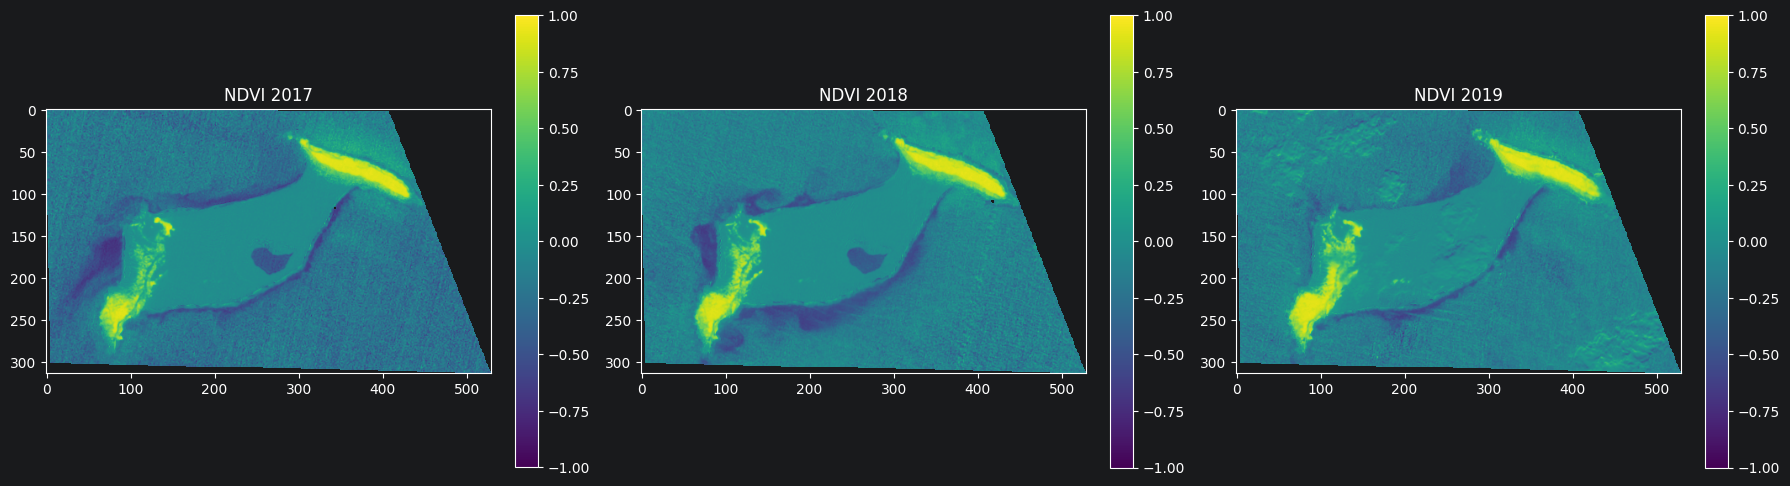

In [234]:
ndvi = {}
for year, files in files_by_year.items():
    b8 = rasterio.open(files[7]).read(1).astype(float)
    b4 = rasterio.open(files[3]).read(1).astype(float)
    ndvi[year] = make_ndi(b8, b4)

plt.close('all')
fig, axes = plt.subplots(1, 3, figsize=(18, 5), tight_layout=True)
for ax, (year, veggie) in zip(axes, ndvi.items()):
    im = ax.imshow(veggie, vmin=-1, vmax=1)
    ax.set_title(f"NDVI {year}")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.show()

In [235]:
for year, files in files_by_year.items():
    print(year, Path(files[7]).name, Path(files[3]).name)

2017 Sentinel-2_L2A_B08_Raw.tiff Sentinel-2_L2A_B04_Raw.tiff
2018 Sentinel-2_L2A_B08_Raw.tiff Sentinel-2_L2A_B04_Raw.tiff
2019 Sentinel-2_L2A_B08_Raw.tiff Sentinel-2_L2A_B04_Raw.tiff


2017: 2095 pixels, 0.18 km²
2018: 2458 pixels, 0.22 km²
2019: 3045 pixels, 0.27 km²


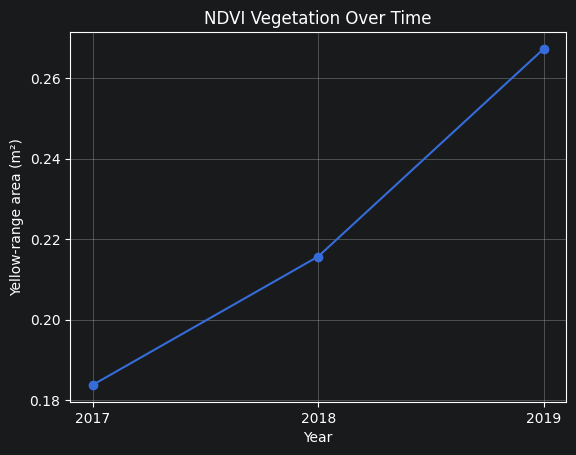

In [310]:
 ndvi = {}

# Calculate NDVI for each year
for year, files in files_by_year.items():
    b8 = rasterio.open(files[7]).read(1).astype(float)
    b4 = rasterio.open(files[3]).read(1).astype(float)
    ndvi[year] = make_ndi(b8, b4)

# Count yellow-range pixels and convert to area
yellow_counts = {}
yellow_area = {}

for year, values in ndvi.items():
    count = np.sum((values >= 0.8) & (values <= 1))
    yellow_counts[year] = count

    file = files_by_year[year][7]
    area = pixel_conversion(file, count)*1e-6
    yellow_area[year] = area

    print(f"{year}: {count} pixels, {area:.2f} km²")

# Plot area over time
years = sorted(yellow_area.keys())
areas = [yellow_area[year] for year in years]

plt.plot(years, areas, marker="o")
plt.xlabel("Year")
plt.ylabel("Yellow-range area (m²)")
plt.title("NDVI Vegetation Over Time")
plt.grid(True)
plt.show()

In [279]:
files_by_year = {"2017": files_2017, "2018": files_2018, "2019": files_2019}

def load_b12(files):
    # look up by name
    f = [x for x in files if "B12_Raw" in x.name][0]
    with rasterio.open(f) as src:
        b12 = src.read(1).astype(float)
    b12[b12 <= 0] = np.nan                      # treat 0 / no-data as invalid
    return b12

def normalise_b12(b12):
    """Robust z-score relative to the ocean level of this image."""
    med = np.nanmedian(b12)
    mad = np.nanmedian(np.abs(b12 - med))
    sigma = 1.4826 * mad
    return (b12 - med) / sigma, med, sigma

b12_raw, b12_z = {}, {}
for year, files in files_by_year.items():
    b12_raw[year] = load_b12(files)
    b12_z[year], med, sigma = normalise_b12(b12_raw[year])
    print(f"{year}: ocean median = {med:.5f}, ocean sigma = {sigma:.5f}")

2017: ocean median = 0.00320, ocean sigma = 0.00104
2018: ocean median = 0.00770, ocean sigma = 0.00341
2019: ocean median = 0.00830, ocean sigma = 0.00460


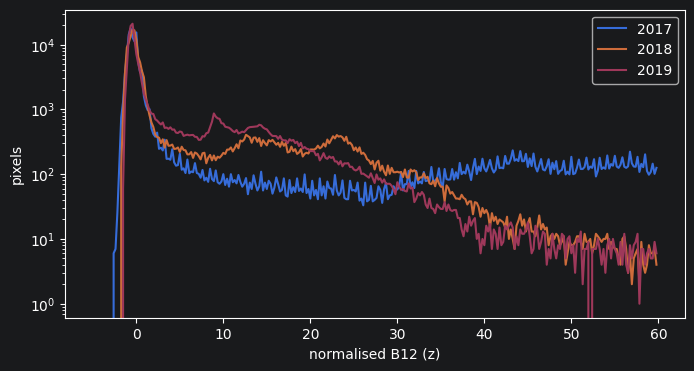

In [280]:
plt.close('all')
fig, ax = plt.subplots(figsize=(8, 4))
for year, z in b12_z.items():
    h, e = np.histogram(z[np.isfinite(z)], bins=np.linspace(-5, 60, 300))
    ax.plot(e[:-1], h, label=year)
ax.semilogy()
ax.set_xlabel("normalised B12 (z)"); ax.set_ylabel("pixels"); ax.legend()
plt.show()

In [295]:
import numpy as np
from scipy import ndimage as ndi

def remove_small_objects(mask, min_size=500, connectivity=2, fill_holes=False):
    """
    Remove connected blobs of True pixels smaller than min_size (in pixels).

    connectivity: 1 = 4-neighbour (edges only), 2 = 8-neighbour (edges and diagonals)
    fill_holes:   also fill enclosed holes in the blobs that are kept
    """
    structure = ndi.generate_binary_structure(2, connectivity)
    lab, n = ndi.label(mask, structure=structure)
    if n == 0:
        return mask.copy()

    sizes = ndi.sum(mask, lab, index=np.arange(1, n + 1))
    keep_labels = np.where(sizes >= min_size)[0] + 1
    cleaned = np.isin(lab, keep_labels)

    if fill_holes:
        cleaned = ndi.binary_fill_holes(cleaned)
    return cleaned

2017: 36962 land px  (no blob filter)
2018: 32837 land px  (no blob filter)
2019: 31861 land px  (blob filter min_size=4000, removed 7338 px)


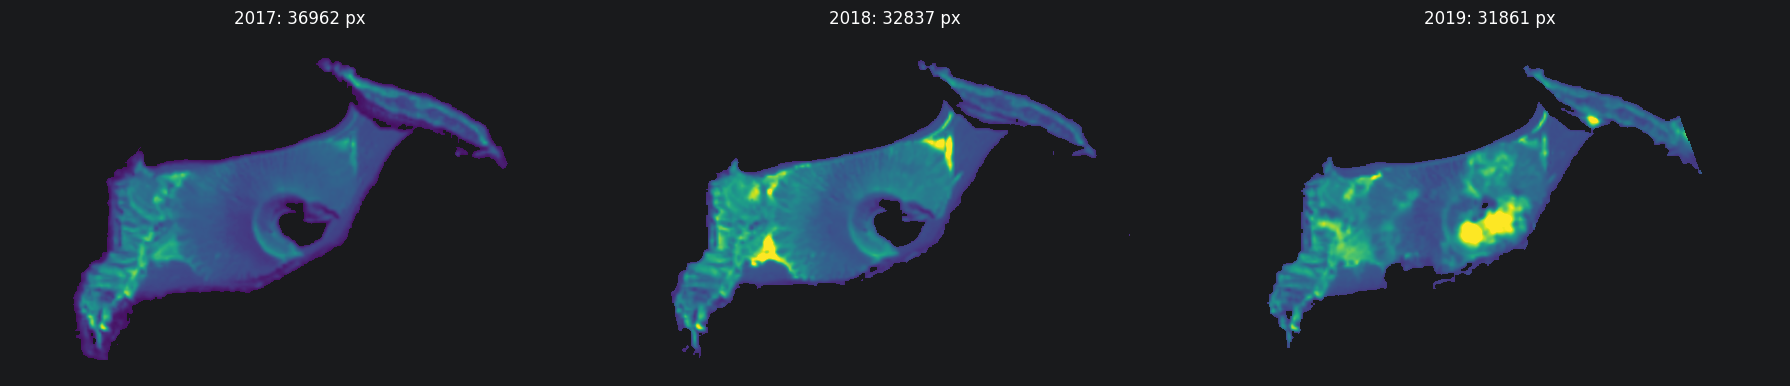

In [317]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

files_by_year = {"2017": files_2017, "2018": files_2018, "2019": files_2019}

Z_THRESH = 5.0                      # same normalised threshold for every year
MIN_SIZE_BY_YEAR = {"2019": 4000}   # only these years get cloud removal {year: min_size}

# ---------- load and normalise B12 ----------
def load_b12(files):
    f = [x for x in files if "B12_Raw" in x.name][0]      # by name, not index
    with rasterio.open(f) as src:
        b12 = src.read(1).astype(float)
    b12[b12 <= 0] = np.nan                                # 0 / no-data -> invalid
    return b12

def normalise_b12(b12):
    """Robust z-score relative to this image's ocean level."""
    med = np.nanmedian(b12)
    sigma = 1.4826 * np.nanmedian(np.abs(b12 - med))
    return (b12 - med) / sigma, med, sigma

b12_raw, b12_z = {}, {}
for year, files in files_by_year.items():
    b12_raw[year] = load_b12(files)
    b12_z[year], med, sigma = normalise_b12(b12_raw[year])


land_masks, n_land = {}, {}
for year, z in b12_z.items():
    land = np.isfinite(z) & (z > Z_THRESH)
    n_before = int(land.sum())

    if year in MIN_SIZE_BY_YEAR:
        lab, n = ndi.label(land)
        if n:
            sizes = ndi.sum(land, lab, range(1, n + 1))
            land = np.isin(lab, 1 + np.where(sizes >= MIN_SIZE_BY_YEAR[year])[0])

    land_masks[year] = land
    n_land[year] = int(land.sum())
    note = f"  (blob filter min_size={MIN_SIZE_BY_YEAR[year]}, removed {n_before - n_land[year]} px)" \
           if year in MIN_SIZE_BY_YEAR else "  (no blob filter)"
    print(f"{year}: {n_land[year]} land px{note}")

# ---------- plot ----------
vmax = np.nanpercentile(b12_raw["2019"], 99.5)
plt.close('all')
fig, axes = plt.subplots(1, len(files_by_year), figsize=(6 * len(files_by_year), 5), tight_layout=True)
for ax, year in zip(axes, files_by_year):
    ax.imshow(np.ma.masked_array(b12_raw[year], mask=~land_masks[year]),
              vmin=0, vmax=vmax, cmap="viridis")
    ax.set_title(f"{year}: {n_land[year]} px")
    ax.axis("off")
plt.show()

2017: 36962 pixels, 3243377 m², 3.243 km²
2018: 32837 pixels, 2881412 m², 2.881 km²
2019: 31861 pixels, 2795769 m², 2.796 km²


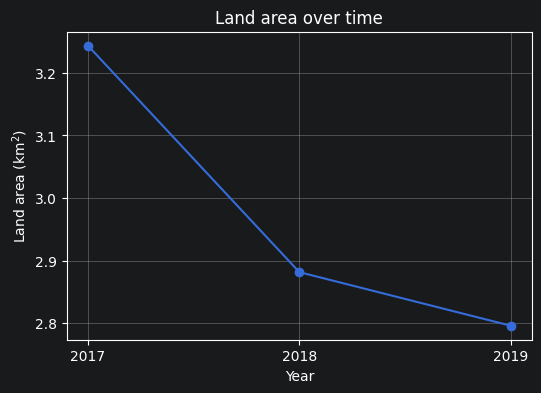

In [320]:
land_area_m2 = {}

for year, count in n_land.items():
    # pick the file by name rather than files_by_year[year][7], since list order isn't guaranteed
    file = [f for f in files_by_year[year] if "B12_Raw" in f.name][0]
    land_area_m2[year] = pixel_conversion(file, count)

    print(f"{year}: {count} pixels, {land_area_m2[year]:.0f} m², {land_area_m2[year] / 1e6:.3f} km²")

# Plot land area over time
years = sorted(land_area_m2.keys())
areas_km2 = [land_area_m2[y] * 1e-6 for y in years]

plt.close('all')
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([int(y) for y in years], areas_km2, marker="o")
ax.set_xticks([int(y) for y in years])
ax.set_xlabel("Year")
ax.set_ylabel("Land area (km$^2$)")
ax.set_title("Land area over time")
ax.grid(True)
plt.show()

2017: land = 3.243 km², vegetation = 0.554 km², ratio = 0.171
2018: land = 2.881 km², vegetation = 0.590 km², ratio = 0.205
2019: land = 2.796 km², vegetation = 0.632 km², ratio = 0.226


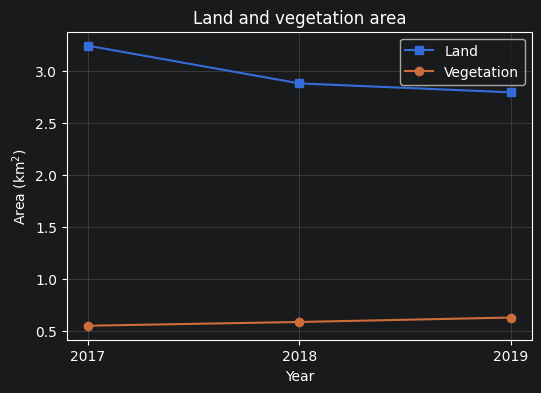

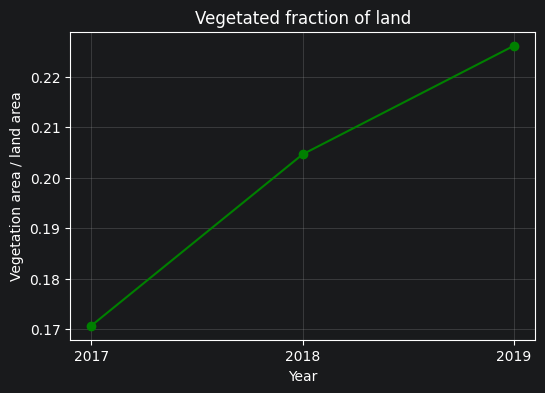

In [319]:
VEG_LO, VEG_HI = 0.3, 1.0

years = sorted(n_land.keys())
land_px, veg_px, land_km2, veg_km2 = {}, {}, {}, {}

for year in years:
    file = [f for f in files_by_year[year] if "B12_Raw" in f.name][0]

    veg_mask = land_masks[year] & (ndvi[year] >= VEG_LO) & (ndvi[year] <= VEG_HI)
    land_px[year] = int(land_masks[year].sum())
    veg_px[year] = int(veg_mask.sum())

    land_km2[year] = pixel_conversion(file, land_px[year]) / 1e6
    veg_km2[year] = pixel_conversion(file, veg_px[year]) / 1e6

    print(f"{year}: land = {land_km2[year]:.3f} km², vegetation = {veg_km2[year]:.3f} km², "
          f"ratio = {veg_px[year] / land_px[year]:.3f}")

x = [int(y) for y in years]
land_a = [land_km2[y] for y in years]
veg_a = [veg_km2[y] for y in years]
ratio = [veg_px[y] / land_px[y] for y in years]

plt.close('all')

# Plot 1: land and vegetation area on the same axes
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x, land_a, "s-", label="Land")
ax.plot(x, veg_a, "o-", label="Vegetation")
ax.set_xticks(x)
ax.set_xlabel("Year")
ax.set_ylabel("Area (km$^2$)")
ax.set_title("Land and vegetation area")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Plot 2: vegetation as a fraction of land
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x, ratio, "o-", color="green")
ax.set_xticks(x)
ax.set_xlabel("Year")
ax.set_ylabel("Vegetation area / land area")
ax.set_title("Vegetated fraction of land")
ax.grid(alpha=0.3)
plt.show()